# Model Training

This notebook trains and evaluates three classification models to predict whether a university student is academically at risk.

**Steps:**
1. Load and inspect the dataset
2. Split into features and target
3. Train / test split (stratified 80/20)
4. Feature scaling (for Logistic Regression only)
5. Train Logistic Regression, Decision Tree, and Random Forest
6. Evaluate and compare models (Accuracy, Precision, Recall, F1, ROC-AUC)
7. Plot feature importances
8. Save model artifacts for the web app

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
)
import joblib

sns.set_style('whitegrid')

## 1. Load Dataset

In [3]:
data_path = Path("../data/students_dataset.csv")
df = pd.read_csv(data_path)

print(f"Shape: {df.shape}")
print(f"\nClass distribution (at_risk):")
print(df['at_risk'].value_counts())
print(f"\nAt-risk rate: {df['at_risk'].mean():.1%}")
df.head()

Shape: (1000, 9)

Class distribution (at_risk):
at_risk
0    659
1    341
Name: count, dtype: int64

At-risk rate: 34.1%


,student_id,study_time_weekly,absences,sleep_hours,stress_level,parental_support,tutoring,extracurricular,at_risk
0,1,19.2,0,8.2,4,1,0,0,0
1,2,22.2,17,3.6,7,0,0,0,1
2,3,7.0,19,3.2,4,4,1,0,1
3,4,17.7,0,8.3,3,3,1,1,0
4,5,6.5,10,3.7,7,0,1,1,1


## 2. Feature and Target Split

`student_id` is dropped as it carries no predictive information.

In [4]:
X = df.drop(columns=['student_id', 'at_risk'])
y = df['at_risk']

print("Features:", list(X.columns))

Features: ['study_time_weekly', 'absences', 'sleep_hours', 'stress_level', 'parental_support', 'tutoring', 'extracurricular']


## 3. Train / Test Split

An 80/20 stratified split preserves the class ratio across both sets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train: {X_train.shape[0]} samples  |  Test: {X_test.shape[0]} samples")
print(f"At-risk rate — train: {y_train.mean():.1%}  |  test: {y_test.mean():.1%}")

Train: 800 samples  |  Test: 200 samples
At-risk rate — train: 34.1%  |  test: 34.0%


## 4. Feature Scaling

`StandardScaler` is fit **only on the training set** and then applied to both sets - this prevents data leakage.

Scaling is applied only for Logistic Regression, which is sensitive to feature magnitude. Decision Tree and Random Forest do not require it.

In [6]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

## 5. Model Training

Three models are trained for comparison:
- **Logistic Regression** — linear baseline, trained on scaled features
- **Decision Tree** — non-linear, interpretable
- **Random Forest** — ensemble of 100 trees, typically more robust

In [7]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("All models trained.")

All models trained.


## 6. Evaluation

Models are evaluated on the held-out test set using five metrics:
- **Accuracy** — overall proportion of correct predictions
- **Precision** — of students predicted at risk, how many truly are
- **Recall** — of students actually at risk, how many were identified
- **F1** — harmonic mean of precision and recall
- **ROC-AUC** — ranking ability across all classification thresholds

In [8]:
models = {
    'LogisticRegression': (lr, X_test_scaled),
    'DecisionTree':       (dt, X_test),
    'RandomForest':       (rf, X_test),
}

rows = []
for name, (model, X_eval) in models.items():
    y_pred  = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]
    rows.append({
        'Model':     name,
        'Accuracy':  round(accuracy_score(y_test, y_pred),  4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall':    round(recall_score(y_test, y_pred),    4),
        'F1':        round(f1_score(y_test, y_pred),        4),
        'ROC-AUC':   round(roc_auc_score(y_test, y_proba),  4),
    })

metrics_df = pd.DataFrame(rows).set_index('Model').sort_values('F1', ascending=False)
metrics_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
LogisticRegression,0.785,0.7119,0.6176,0.6614,0.8509
RandomForest,0.790,0.7321,0.6029,0.6613,0.8907
DecisionTree,0.740,0.6143,0.6324,0.6232,0.7139


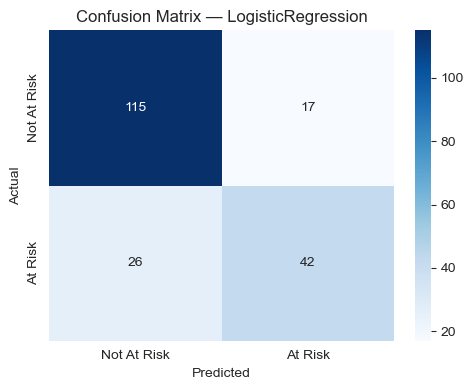

Best model by F1: LogisticRegression


In [9]:
best_name          = metrics_df.index[0]
best_model, best_X = models[best_name]
y_pred_best        = best_model.predict(best_X)

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Not At Risk', 'At Risk'],
    yticklabels=['Not At Risk', 'At Risk'],
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix — {best_name}')
plt.tight_layout()
plt.show()

print(f"Best model by F1: {best_name}")

## 7. Feature Importance

Feature importances from Random Forest and absolute coefficients from Logistic Regression show which indicators drive the predictions.

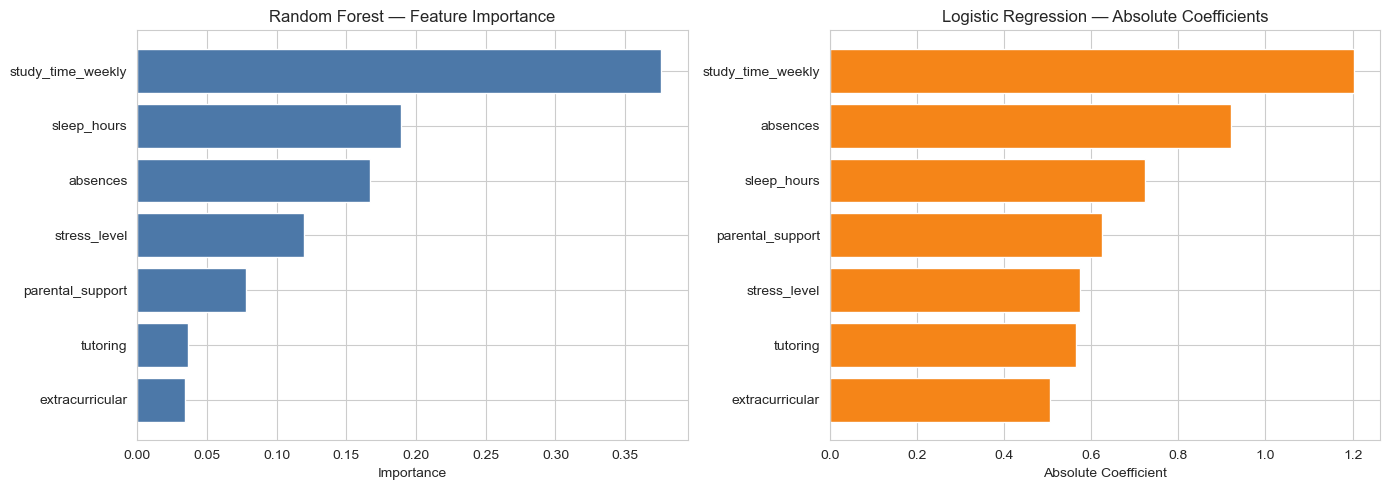

In [10]:
feature_importance_df = pd.DataFrame({
    'feature':             X.columns,
    'RandomForest':        rf.feature_importances_,
    'LogisticRegression':  np.abs(lr.coef_[0]),
}).sort_values('RandomForest', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rf_sorted = feature_importance_df.sort_values('RandomForest')
axes[0].barh(rf_sorted['feature'], rf_sorted['RandomForest'], color='#4C78A8')
axes[0].set_title('Random Forest — Feature Importance')
axes[0].set_xlabel('Importance')

lr_sorted = feature_importance_df.sort_values('LogisticRegression')
axes[1].barh(lr_sorted['feature'], lr_sorted['LogisticRegression'], color='#F58518')
axes[1].set_title('Logistic Regression — Absolute Coefficients')
axes[1].set_xlabel('Absolute Coefficient')

plt.tight_layout()
plt.show()

## 8. Save Artifacts

Saves all models, the scaler, the metrics CSV, and a bundled file used by the Streamlit web app.

In [11]:
out_dir    = Path('..') / 'results'
models_dir = Path('..') / 'models'
out_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

metrics_df.to_csv(out_dir / 'model_metrics.csv')
joblib.dump(scaler, out_dir / 'scaler.joblib')

for name, (model, _) in models.items():
    joblib.dump(model, out_dir / f'{name}.joblib')

best_model_name = metrics_df.index[0]
bundle = {
    'model_name':    best_model_name,
    'model':         models[best_model_name][0],
    'scaler':        scaler if best_model_name == 'LogisticRegression' else None,
    'feature_names': list(X.columns),
}
joblib.dump(bundle, models_dir / 'student_risk_model.joblib')

print(f"Saved: metrics CSV, scaler, 3 models, and best-model bundle")
print(f"Best model: {best_model_name}")

Saved: metrics CSV, scaler, 3 models, and best-model bundle
Best model: LogisticRegression
